# TP3 — Tarefa 1: Regressão linear sobre o dataset

**Projeto de Bloco: Análise e Segurança de Sistemas Inteligentes — transição T1 → T2**

O TP3 consolida o que o Trimestre 1 construiu e prepara o Trimestre 2. Esta **Tarefa 1**
implementa um modelo de **regressão linear múltipla** com pipeline completo
(pré-processamento + `LinearRegression`), calcula **R² e RMSE**, analisa os resíduos com
**residual plot** e **Q-Q plot** e documenta as limitações do modelo. A Tarefa 5
(pergunta de classificação) está formalizada em `pergunta_classificacao.md`, na mesma pasta.


## 1. Escolha do alvo: uma variável numérica derivada do texto

A tarefa final do projeto é **classificação** (inferir a intenção de um ticket), mas este TP
pede um exercício de regressão usando uma variável numérica **derivada** como alvo. Candidatas
no dataset (versão limpa, `data/customer_support_tickets_clean.csv`):

| Candidata | Cobertura | Problema |
|---|---|---|
| `Desc_Len` — comprimento da descrição (caracteres) | 8.469 (100%) | — |
| `Customer Satisfaction Rating` (escala 1–5) | 2.769 (só fechados) | ordinal e discreta; viés de seleção |
| `Resolution_Duration_Hours` | 2.769 (só fechados) | ~49% negativas (anomalia documentada no EDA) |

**Escolha: `Desc_Len`** — já derivada na limpeza do EDA (caso "comprimento do texto" sugerido
no enunciado), disponível para todos os tickets (sem viés de seleção) e conectada ao eixo de
texto que o Trimestre 2 vai modelar. As outras duas restringiriam a análise aos 2.769 tickets
fechados e carregam anomalias já documentadas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import r2_score, root_mean_squared_error

RANDOM_STATE = 42

# Paleta do projeto (mesmo sistema visual do EDA): superfície clara, tinta
# primária/secundária, grade recessiva — série única em azul.
SURFACE   = "#fcfcfb"
INK       = "#0b0b0b"
SECONDARY = "#52514e"
MUTED     = "#898781"
GRID      = "#e1e0d9"
BASELINE  = "#c3c2b7"
BLUE      = "#2a78d6"   # série / sequencial azul
RED       = "#e34948"   # polo negativo do par divergente azul↔vermelho

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.grid": True,
    "axes.axisbelow": True,
    "font.size": 10,
})

In [2]:
df = pd.read_csv("../data/customer_support_tickets_clean.csv")

NUMERIC = ["Customer Age", "Purchase_to_Ticket_Months", "Hour_of_First_Response"]
CATEGORICAL = ["Ticket Type", "Ticket Subject", "Ticket Status",
               "Ticket Priority", "Ticket Channel", "Customer Gender"]
TARGET = "Desc_Len"

X = df[NUMERIC + CATEGORICAL]
y = df[TARGET]

print(f"Registros: {len(df):,}  |  features: {X.shape[1]} (3 numéricas + 6 categóricas)  |  alvo: {TARGET}")
print()
print("Valores ausentes por coluna (tratados no pipeline):")
print(X.isna().sum().to_frame("nulos").T)
print()
print(f"Alvo: min={y.min()}  média={y.mean():.1f}  mediana={y.median():.0f}  max={y.max()}  σ={y.std():.1f}")

Registros: 8,469  |  features: 9 (3 numéricas + 6 categóricas)  |  alvo: Desc_Len

Valores ausentes por coluna (tratados no pipeline):
       Customer Age  Purchase_to_Ticket_Months  Hour_of_First_Response  \
nulos             0                          0                    2819   

       Ticket Type  Ticket Subject  Ticket Status  Ticket Priority  \
nulos            0               0              0                0   

       Ticket Channel  Customer Gender  
nulos               0                0  

Alvo: min=135  média=282.0  mediana=290  max=402  σ=44.0


## 2. Sinal a priori: η² do alvo contra as camadas de rótulo

Antes de ajustar qualquer modelo, medimos a variância do alvo explicável **no melhor caso**
pelas camadas de rótulo disponíveis — η² = variância entre grupos / variância total, ou seja, o
R² máximo que um modelo *perfeito* sobre aquela variável categórica poderia atingir. Se η² ≈ 0,
nenhum modelo linear sobre essas features pode ter R² substancial; o resultado da regressão
deixa de ser surpresa e passa a ser verificação.


In [3]:
def eta2(grupos):
    ss_b = (grupos.apply(lambda s: (s.mean() - y.mean()) ** 2 * len(s))).sum()
    ss_t = ((y - y.mean()) ** 2).sum()
    return ss_b / ss_t

print("Variância do alvo explicável no melhor caso (η² = R² máximo teórico):")
for coluna in ["Ticket Type", "Ticket Subject"]:
    print(f"  η² Desc_Len ~ {coluna:15s} = {eta2(df.groupby(coluna)[TARGET]):.4f}")

Variância do alvo explicável no melhor caso (η² = R² máximo teórico):
  η² Desc_Len ~ Ticket Type     = 0.0007
  η² Desc_Len ~ Ticket Subject  = 0.0009


## 3. Distribuição do alvo

`Desc_Len` é moderadamente simétrica (média 282, mediana 290 — leve assimetria à esquerda), mas
**truncada** em [135, 402] caracteres e discreta (contagem de caracteres). Essas duas
propriedades reaparecerão na análise de resíduos: um alvo limitado tende a produzir caudas
não-normais nos resíduos.


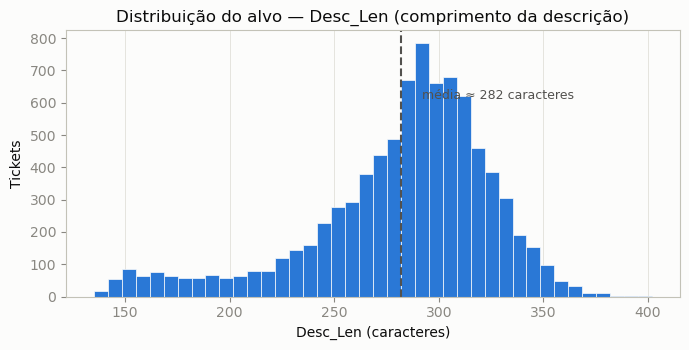

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
counts, bins, _ = ax.hist(y, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.axvline(y.mean(), color=SECONDARY, linewidth=1.5, linestyle="--")
ax.annotate(f"média ≈ {y.mean():.0f} caracteres",
            xy=(y.mean(), 0), xytext=(y.mean() + 10, counts.max() * 0.78),
            color=SECONDARY, fontsize=9)
ax.set_title("Distribuição do alvo — Desc_Len (comprimento da descrição)")
ax.set_xlabel("Desc_Len (caracteres)")
ax.set_ylabel("Tickets")
ax.grid(axis="y")
fig.tight_layout()
plt.show()

## 4. Pipeline de regressão (pré-processamento + LinearRegression múltipla)

Pipeline do `scikit-learn`:

1. **Numéricas** (`Customer Age`, `Purchase_to_Ticket_Months`, `Hour_of_First_Response`):
   imputação da mediana (a hora da 1ª resposta tem 2.819 nulos — os tickets `Open`, ainda não
   respondidos) + padronização (`StandardScaler`);
2. **Categóricas** (`Ticket Type`, `Ticket Subject`, `Ticket Status`, `Ticket Priority`,
   `Ticket Channel`, `Customer Gender`): one-hot encoding (`drop="first"` para evitar
   colinearidade com o intercepto);
3. **Modelo**: `LinearRegression` (mínimos quadrados).

Divisão treino/teste 80/20 com `random_state=42`. São 32 preditores após o encoding.


In [5]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),  # Hour_of_First_Response: 2.819 nulos
        ("scaler", StandardScaler()),
    ]), NUMERIC),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore",
                          sparse_output=False), CATEGORICAL),
])

pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression()),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

pipeline.fit(X_train, y_train)
y_pred_train = pipeline.predict(X_train)
y_pred_test = pipeline.predict(X_test)

n_features = pipeline.named_steps["preprocess"].get_feature_names_out().shape[0]
print(f"Pipeline ajustado. Preditores após encoding: {n_features}  |  treino: {len(X_train):,}  |  teste: {len(X_test):,}")

Pipeline ajustado. Preditores após encoding: 32  |  treino: 6,775  |  teste: 1,694


## 5. Métricas: R² e RMSE

Avaliação no treino, no teste e por **validação cruzada (5-fold)**, sempre comparada a um
**baseline** que ignora as features e prevê a média do alvo. Se o modelo linear não superar o
baseline, as features não carregam sinal linear — conclusão que o EDA já antecipava.


In [6]:
def metricas(y_true, y_pred, nome):
    r2 = r2_score(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    print(f"  {nome:8s}  R² = {r2:+.4f}   RMSE = {rmse:6.2f} caracteres")
    return r2, rmse

print(f"Referência: σ(y treino) = {y_train.std():.2f} — com R² ≈ 0, RMSE ≈ σ(y)")
print("LinearRegression múltipla:")
metricas(y_train, y_pred_train, "Treino")
metricas(y_test, y_pred_test, "Teste")

Referência: σ(y treino) = 43.81 — com R² ≈ 0, RMSE ≈ σ(y)
LinearRegression múltipla:
  Treino    R² = +0.0041   RMSE =  43.72 caracteres
  Teste     R² = -0.0002   RMSE =  44.73 caracteres


(-0.000221805605226999, 44.72514411037263)

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Validação cruzada (5-fold) — modelo vs baseline que prevê a média:")
for nome, modelo in [("LinearRegression", LinearRegression()),
                     ("Baseline (média)", DummyRegressor(strategy="mean"))]:
    pipe = Pipeline([("preprocess", preprocessor), ("model", modelo)])
    r2_cv = cross_val_score(pipe, X, y, cv=kf, scoring="r2")
    rmse_cv = -cross_val_score(pipe, X, y, cv=kf,
                               scoring="neg_root_mean_squared_error")
    print(f"  {nome:18s}  R² = {r2_cv.mean():+.4f} ± {r2_cv.std():.4f}   "
          f"RMSE = {rmse_cv.mean():6.2f} ± {rmse_cv.std():.2f}")

Validação cruzada (5-fold) — modelo vs baseline que prevê a média:


  LinearRegression    R² = -0.0049 ± 0.0034   RMSE =  44.08 ± 0.72


  Baseline (média)    R² = -0.0009 ± 0.0010   RMSE =  43.99 ± 0.68


## 6. Coeficientes: existe algum preditor com efeito?

Mesmo com R² ≈ 0, inspecionamos os maiores coeficientes para descartar efeitos locais
relevantes. A escala é interpretável: **β = caracteres por unidade do preditor** (as numéricas
foram padronizadas).


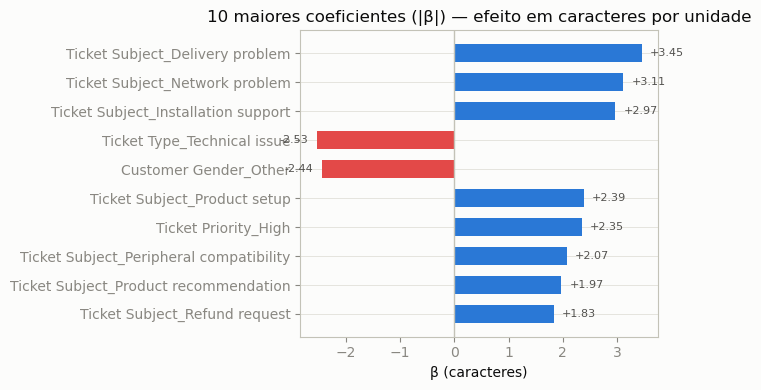

In [8]:
model = pipeline.named_steps["model"]
nomes = pipeline.named_steps["preprocess"].get_feature_names_out()
coef = pd.Series(model.coef_, index=nomes)
coef.index = [n.replace("num__", "").replace("cat__", "") for n in coef.index]
top = coef.sort_values(key=np.abs, ascending=False).head(10)

fig, ax = plt.subplots(figsize=(7, 4))
cores = [BLUE if v >= 0 else RED for v in top.values]
ax.barh(top.index[::-1], top.values[::-1], color=cores[::-1], height=0.62)
ax.axvline(0, color=BASELINE, linewidth=1)
for i, v in enumerate(top.values[::-1]):
    ax.text(v + (0.15 if v >= 0 else -0.15), i, f"{v:+.2f}",
            va="center", ha="left" if v >= 0 else "right",
            fontsize=8, color=SECONDARY)
ax.set_title("10 maiores coeficientes (|β|) — efeito em caracteres por unidade")
ax.set_xlabel("β (caracteres)")
ax.grid(axis="x")
fig.tight_layout()
plt.show()

## 7. Análise de resíduos

Premissas da regressão linear a verificar nos resíduos (y − ŷ) do **teste**:

- **linearidade e homocedasticidade** → residual plot (sem forma/funil);
- **normalidade** → histograma + Q-Q plot + teste de Shapiro-Wilk.


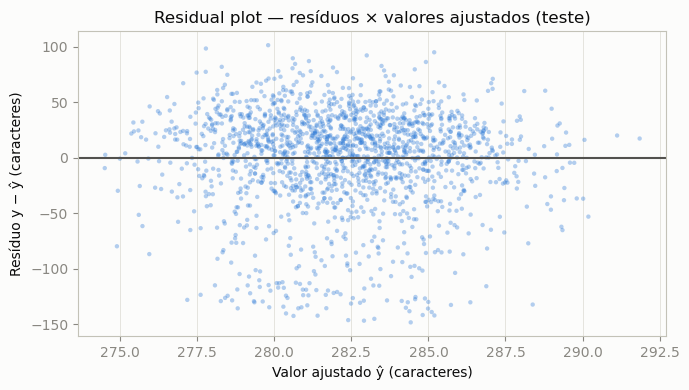

Resíduos (teste): média = -1.22  σ = 44.72  mín = -148  máx = 101


In [9]:
residuos = y_test - y_pred_test
ajustados = y_pred_test

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(ajustados, residuos, s=10, alpha=0.35, color=BLUE, edgecolors="none")
ax.axhline(0, color=SECONDARY, linewidth=1.5)
ax.set_title("Residual plot — resíduos × valores ajustados (teste)")
ax.set_xlabel("Valor ajustado ŷ (caracteres)")
ax.set_ylabel("Resíduo y − ŷ (caracteres)")
ax.grid(axis="y")
fig.tight_layout()
plt.show()

print(f"Resíduos (teste): média = {residuos.mean():+.2f}  σ = {residuos.std():.2f}  "
      f"mín = {residuos.min():.0f}  máx = {residuos.max():.0f}")

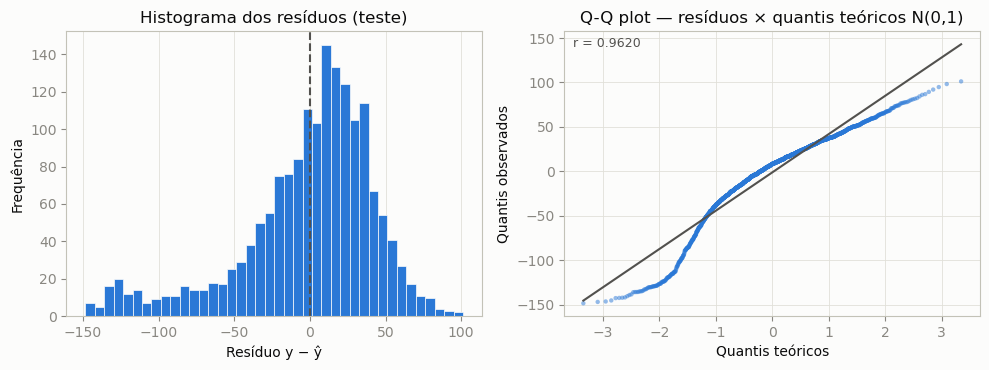

Shapiro-Wilk: p = 2.88e-28  →  REJEITA normalidade (p < 0,05)
Assimetria = -1.08   Curtose = +1.21


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

axes[0].hist(residuos, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[0].axvline(0, color=SECONDARY, linewidth=1.5, linestyle="--")
axes[0].set_title("Histograma dos resíduos (teste)")
axes[0].set_xlabel("Resíduo y − ŷ")
axes[0].set_ylabel("Frequência")
axes[0].grid(axis="y")

res = stats.probplot(residuos, dist="norm", plot=None, rvalue=True)
osm, osr = res[0]
slope, intercept, r = res[1]
axes[1].scatter(osm, osr, s=10, alpha=0.5, color=BLUE, edgecolors="none")
axes[1].plot(osm, slope * osm + intercept, color=SECONDARY, linewidth=1.5)
axes[1].set_title("Q-Q plot — resíduos × quantis teóricos N(0,1)")
axes[1].set_xlabel("Quantis teóricos")
axes[1].set_ylabel("Quantis observados")
axes[1].text(0.02, 0.98, f"r = {r:.4f}", transform=axes[1].transAxes,
             va="top", fontsize=9, color=SECONDARY)

fig.tight_layout()
plt.show()

shapiro_p = stats.shapiro(residuos).pvalue
print(f"Shapiro-Wilk: p = {shapiro_p:.2e}  →  "
      f"{'não rejeita normalidade' if shapiro_p > 0.05 else 'REJEITA normalidade (p < 0,05)'}")
print(f"Assimetria = {stats.skew(residuos):+.2f}   Curtose = {stats.kurtosis(residuos):+.2f}")

## 8. Limitações e próximos passos

**O que este modelo é.** Um exercício de consolidação estatística: aplica o pipeline completo de
regressão e *mede* — em vez de supor — que o dataset não sustenta predição linear do
comprimento do texto.

**Limitações observadas (e por quê).**

1. **R² ≈ 0 e RMSE ≈ σ(y) ≈ 44.** No teste, R² = −0,0002 com RMSE = 44,7 ≈ σ. Na validação
   cruzada, o modelo fica marginalmente **abaixo** do baseline que prevê a média (R² ≈ −0,005
   vs ≈ −0,001): os 32 graus de liberdade adicionais só ajustam ruído. Isso é consistente com a
   Seção 2 (η² ≤ 0,001 para as duas camadas de rótulo) e com o EDA (V de Cramér ≤ 0,034 entre
   categóricas; correlações ≈ 0 entre numéricas; |rank-biserial| ≤ 0,04 nos testes formais): o
   dataset é **sintético** e as variáveis foram geradas sem associação.
2. **Resíduos não-normais.** Shapiro-Wilk rejeita normalidade (p = 2,9e−28) e o Q-Q plot afasta
   da reta nas caudas (assimetria −1,08; curtose +1,21). Causa estrutural: o alvo é **truncado
   em [135, 402]** e **discreto** — a normalidade dos resíduos é violada por construção, não por
   falha do ajuste.
3. **Artefatos sintéticos contaminam o alvo.** ≈69% das descrições seguem template fixo e 364
   registros ainda contêm o placeholder `{product_purchased}` — o alvo "comprimento do texto"
   é em boa parte um artefato do gerador, não sinal de linguagem real.
4. **Ausência de relação linear não implica ausência de relação.** As mesmas features podem
   carregar sinal **não-linear** ou interativo — este modelo não o detectaria. E o sinal que
   importa (a *intenção* por trás do texto) não é função linear de metadados; é problema de
   classificação sobre texto (Tarefa 5).
5. **Não generaliza.** Um R² de 0 em dados sintéticos não informa sobre tickets reais; o modelo
   não deve ser usado em produção para nada — sua utilidade é documentar a fronteira da fase
   analítica.

**Próximos passos (Trimestre 2).**

- Formalizar e treinar o **classificador de intenção** (5 classes de `Ticket Type`) sobre
  TF-IDF do texto normalizado — ver `pergunta_classificacao.md`;
- Substituir o placeholder de `/predict` na API (`fastapi/routes/predict.py`) pelo modelo
  treinado, mantendo a superfície auditada (JWT, rate limit, validação);
- Métricas de classificação: accuracy, **F1 macro** (classes balanceadas) e matriz de confusão.


## Conclusão

A regressão linear cumpriu seu papel de consolidação: o pipeline está completo e replicável, as
métricas (R² ≈ 0, RMSE ≈ σ) quantificam a ausência de sinal linear e a análise de resíduos
documenta a violação de normalidade esperada de um alvo truncado e sintético. O resultado
**não é um fracasso do modelo — é a evidência de que a pergunta do projeto é de classificação**,
e é exatamente essa transição que a Tarefa 5 formaliza.
